In [17]:
# %% เซลล์ 1 (v7): ดึงข้อมูล PM2.5 ล่าสุดจาก Air4Thai (endpoint จริง + แก้ SSL)
import requests
import pandas as pd
from datetime import datetime, timedelta
import urllib3

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)  # ปิด warning จาก verify=False

headers_air4thai = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

today = datetime.now()
sdate = (today - timedelta(days=3)).strftime("%Y-%m-%d")  # ย้อนหลัง 3 วันเผื่อ buffer
edate = today.strftime("%Y-%m-%d")

url = "https://air4thai.com/forweb/getHistoryData.php"
params = {
    "stationID": "46t",
    "param": "PM25",
    "type": "hr",
    "sdate": sdate,
    "edate": edate,
    "stime": "00",
    "etime": "23"
}

r = requests.get(url, params=params, headers=headers_air4thai, timeout=15, verify=False)
print("Status:", r.status_code)
print("Response (500 ตัวแรก):", r.text[:500])

Status: 200
Response (500 ตัวแรก): {"result":"OK","error":"","stations":[{"stationID":"46t","params":["PM25"],"data":[{"DATETIMEDATA":"2026-07-05 00:00:00","PM25":19.7},{"DATETIMEDATA":"2026-07-05 01:00:00","PM25":12.2},{"DATETIMEDATA":"2026-07-05 02:00:00","PM25":17.2},{"DATETIMEDATA":"2026-07-05 03:00:00","PM25":21.8},{"DATETIMEDATA":"2026-07-05 04:00:00","PM25":16},{"DATETIMEDATA":"2026-07-05 05:00:00","PM25":15.9},{"DATETIMEDATA":"2026-07-05 06:00:00","PM25":13.1},{"DATETIMEDATA":"2026-07-05 07:00:00","PM25":15.8},{"DATETIMED


In [18]:
# %% เซลล์ 2: parse response เป็น DataFrame + แปลง timezone เป็น UTC

result = r.json()
records = result["stations"][0]["data"]

df_recent = pd.DataFrame(records)
df_recent = df_recent.rename(columns={"DATETIMEDATA": "datetime_utc", "PM25": "pm25"})
df_recent["datetime_utc"] = pd.to_datetime(df_recent["datetime_utc"])

# Air4Thai รายงานเวลาแบบ Thailand time (UTC+7) ต้องแปลงเป็น UTC ให้ตรงกับที่ใช้เทรนโมเดล
df_recent["datetime_utc"] = df_recent["datetime_utc"].dt.tz_localize("Asia/Bangkok").dt.tz_convert("UTC")

df_recent = df_recent.dropna(subset=["pm25"]).sort_values("datetime_utc").reset_index(drop=True)

print(f"ดึงข้อมูลได้ {len(df_recent)} แถว")
print(f"ช่วงเวลา (UTC): {df_recent['datetime_utc'].min()} → {df_recent['datetime_utc'].max()}")
df_recent.tail(10)

ดึงข้อมูลได้ 89 แถว
ช่วงเวลา (UTC): 2026-07-04 17:00:00+00:00 → 2026-07-08 09:00:00+00:00


,datetime_utc,pm25
79,2026-07-08 00:00:00+00:00,18.0
80,2026-07-08 01:00:00+00:00,19.1
81,2026-07-08 02:00:00+00:00,20.8
82,2026-07-08 03:00:00+00:00,16.1
83,2026-07-08 04:00:00+00:00,17.9
84,2026-07-08 05:00:00+00:00,16.0
85,2026-07-08 06:00:00+00:00,16.2
86,2026-07-08 07:00:00+00:00,20.8
87,2026-07-08 08:00:00+00:00,17.0
88,2026-07-08 09:00:00+00:00,17.9


In [19]:
# %% เซลล์ 2b (ถ้าจำเป็น): ดึงพิกัดสถานี 7747 จาก OpenAQ อีกครั้ง
r_loc = requests.get("https://api.openaq.org/v3/locations/7747", headers=headers, timeout=15)
loc_data = r_loc.json()["results"][0]
STATION_LAT = loc_data["coordinates"]["latitude"]
STATION_LON = loc_data["coordinates"]["longitude"]
print(f"พิกัด: {STATION_LAT}, {STATION_LON}")

พิกัด: 16.44538333, 102.83525


In [20]:
# %% เซลล์ 3: ดึงสภาพอากาศปัจจุบัน (ใช้พิกัดสถานี 7747)
url_weather = "https://api.open-meteo.com/v1/forecast"
params_weather = {
    "latitude": STATION_LAT,
    "longitude": STATION_LON,
    "current": "temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation",
    "timezone": "UTC"
}

r_weather = requests.get(url_weather, params=params_weather, timeout=15)
current_weather = r_weather.json()["current"]

print(current_weather)

{'time': '2026-07-08T09:00', 'interval': 900, 'temperature_2m': 32.3, 'relative_humidity_2m': 56, 'wind_speed_10m': 17.9, 'precipitation': 0.0}


In [21]:
# %% เซลล์ 4: ประกอบ feature row ณ เวลาปัจจุบัน
import numpy as np

latest_time = df_recent["datetime_utc"].max()
pm25_series = df_recent.set_index("datetime_utc")["pm25"]

current_features = {
    "temp": current_weather["temperature_2m"],
    "humidity": current_weather["relative_humidity_2m"],
    "wind_speed": current_weather["wind_speed_10m"],
    "precipitation": current_weather["precipitation"],
    "hour_sin": np.sin(2 * np.pi * latest_time.hour / 24),
    "hour_cos": np.cos(2 * np.pi * latest_time.hour / 24),
    "month_sin": np.sin(2 * np.pi * latest_time.month / 12),
    "month_cos": np.cos(2 * np.pi * latest_time.month / 12),
    "dayofweek": latest_time.dayofweek,
    "pm25_lag_1": pm25_series.iloc[-2],   # ค่าเมื่อ 1 ชม.ที่แล้ว (ไม่ใช่ตัวล่าสุด)
    "pm25_lag_3": pm25_series.iloc[-4],
    "pm25_lag_6": pm25_series.iloc[-7],
    "pm25_lag_12": pm25_series.iloc[-13],
    "pm25_lag_24": pm25_series.iloc[-25] if len(pm25_series) > 24 else pm25_series.iloc[0],
    "pm25_roll_mean_6": pm25_series.iloc[-7:-1].mean(),
    "pm25_roll_std_6": pm25_series.iloc[-7:-1].std(),
    "pm25_roll_mean_24": pm25_series.iloc[-25:-1].mean() if len(pm25_series) > 24 else pm25_series.mean(),
    "pm25_roll_std_24": pm25_series.iloc[-25:-1].std() if len(pm25_series) > 24 else pm25_series.std(),
}

X_now = pd.DataFrame([current_features])[feature_cols]
print(X_now)

   temp  humidity  wind_speed  precipitation  hour_sin  hour_cos  month_sin  \
0  32.3        56        17.9            0.0  0.707107 -0.707107       -0.5   

   month_cos  dayofweek  pm25_lag_1  pm25_lag_3  pm25_lag_6  pm25_lag_12  \
0  -0.866025          2        17.0        16.2        16.1         16.0   

   pm25_lag_24  pm25_roll_mean_6  pm25_roll_std_6  pm25_roll_mean_24  \
0         20.2         17.333333         1.845716            17.6125   

   pm25_roll_std_24  
0          2.931732  


In [22]:
# %% เซลล์ 5: พยากรณ์ล่วงหน้า 24 ชม. โดยใช้โมเดลทั้ง 24 horizons
import pickle

with open("models/lgb_pm25_multistep_20260708_153732.pkl", "rb") as f:
    package = pickle.load(f)

forecast_results = []
for h in range(1, 25):
    model = package["models"][h]
    pred = model.predict(X_now)[0]
    forecast_time_utc = latest_time + pd.Timedelta(hours=h)
    forecast_time_th = forecast_time_utc.tz_convert("Asia/Bangkok")
    forecast_results.append({
        "datetime_utc": forecast_time_utc,
        "datetime_th": forecast_time_th,
        "horizon": h,
        "pm25_pred": round(pred, 1)
    })

df_forecast = pd.DataFrame(forecast_results)
print(f"พยากรณ์จากเวลาปัจจุบัน (UTC): {latest_time}")
print(f"พยากรณ์จากเวลาปัจจุบัน (ไทย): {latest_time.tz_convert('Asia/Bangkok')}")
print()
print(df_forecast[["datetime_th", "horizon", "pm25_pred"]].to_string(index=False))

พยากรณ์จากเวลาปัจจุบัน (UTC): 2026-07-08 09:00:00+00:00
พยากรณ์จากเวลาปัจจุบัน (ไทย): 2026-07-08 16:00:00+07:00

              datetime_th  horizon  pm25_pred
2026-07-08 17:00:00+07:00        1       18.1
2026-07-08 18:00:00+07:00        2       19.0
2026-07-08 19:00:00+07:00        3       18.5
2026-07-08 20:00:00+07:00        4       17.0
2026-07-08 21:00:00+07:00        5       18.0
2026-07-08 22:00:00+07:00        6       17.5
2026-07-08 23:00:00+07:00        7       18.3
2026-07-09 00:00:00+07:00        8       18.0
2026-07-09 01:00:00+07:00        9       17.5
2026-07-09 02:00:00+07:00       10       17.0
2026-07-09 03:00:00+07:00       11       18.7
2026-07-09 04:00:00+07:00       12       18.4
2026-07-09 05:00:00+07:00       13       19.0
2026-07-09 06:00:00+07:00       14       17.7
2026-07-09 07:00:00+07:00       15       20.2
2026-07-09 08:00:00+07:00       16       16.6
2026-07-09 09:00:00+07:00       17       17.9
2026-07-09 10:00:00+07:00       18       18.3
2026-07-09 11

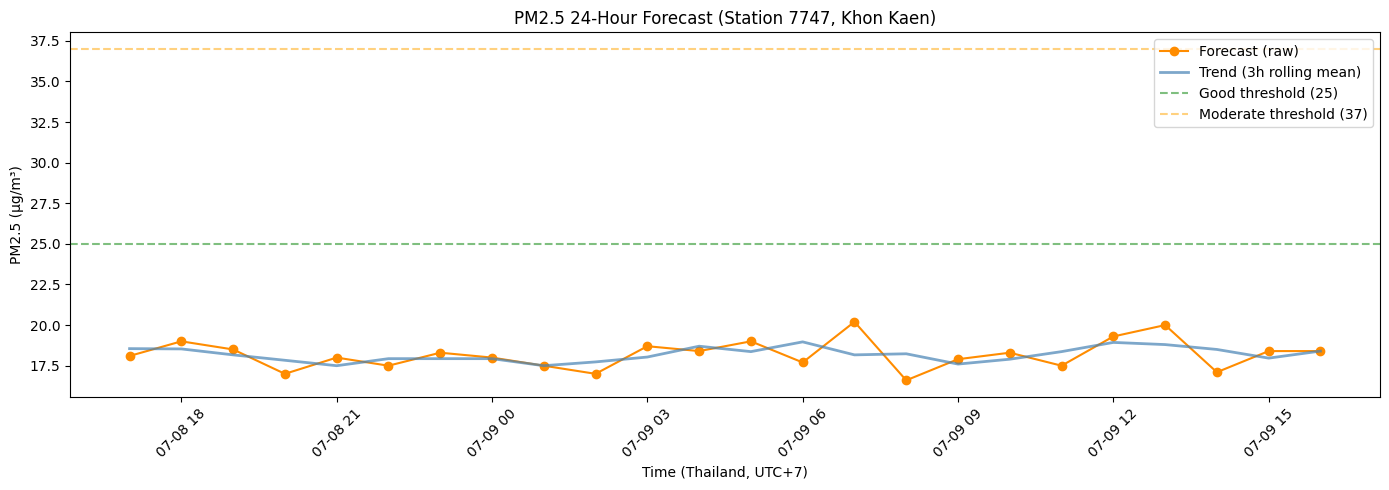

In [24]:
# %% เซลล์: พล็อตกราฟพยากรณ์ 24 ชม. (ภาษาอังกฤษทั้งหมด กันปัญหาฟอนต์ไทย)
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df_forecast["datetime_th"], df_forecast["pm25_pred"], marker="o", color="darkorange", label="Forecast (raw)")

# Rolling mean เพื่อดูแนวโน้มโดยรวม
df_forecast["pm25_smooth"] = df_forecast["pm25_pred"].rolling(3, center=True, min_periods=1).mean()
plt.plot(df_forecast["datetime_th"], df_forecast["pm25_smooth"], color="steelblue", linewidth=2, alpha=0.7, label="Trend (3h rolling mean)")

plt.axhline(y=25, color="green", linestyle="--", alpha=0.5, label="Good threshold (25)")
plt.axhline(y=37, color="orange", linestyle="--", alpha=0.5, label="Moderate threshold (37)")
plt.title("PM2.5 24-Hour Forecast (Station 7747, Khon Kaen)")
plt.xlabel("Time (Thailand, UTC+7)")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig("forecast_test.png", dpi=100)
plt.show()